In [1]:
import sys, subprocess, importlib.util, warnings
warnings.filterwarnings("ignore")
pkgs = {"requests":"requests","pandas":"pandas","numpy":"numpy","matplotlib":"matplotlib","seaborn":"seaborn","sklearn":"scikit-learn","folium":"folium"}
for mod, pkg in pkgs.items():
    if importlib.util.find_spec(mod) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg])
import requests, pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns, folium, sqlite3
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
OUT=Path("capstone_outputs"); OUT.mkdir(exist_ok=True)

In [8]:

import pandas as pd
from pathlib import Path

DATA_DIR = Path(".")

for filename in [
    "dataset_part_1.csv",
    "dataset_part_2.csv",
    "dataset_part_3.csv",
    "spacex_launch_dash.csv"
]:
    filepath = DATA_DIR / filename

    if filepath.exists():
        df = pd.read_csv(filepath)
        print(f"\n{filename}")
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        display(df.head(3))
    else:
        print(f"FILE NOT FOUND: {filepath}")


dataset_part_1.csv
Shape: (90, 17)
Columns: ['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude']


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude
0,1,2010-06-04,Falcon 9,6123.547647,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857



dataset_part_2.csv
Shape: (90, 18)
Columns: ['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude', 'Class']


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6123.547647,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0



dataset_part_3.csv
Shape: (90, 80)
Columns: ['FlightNumber', 'PayloadMass', 'Flights', 'GridFins', 'Reused', 'Legs', 'Block', 'ReusedCount', 'Orbit_ES-L1', 'Orbit_GEO', 'Orbit_GTO', 'Orbit_HEO', 'Orbit_ISS', 'Orbit_LEO', 'Orbit_MEO', 'Orbit_PO', 'Orbit_SO', 'Orbit_SSO', 'Orbit_VLEO', 'LaunchSite_CCSFS SLC 40', 'LaunchSite_KSC LC 39A', 'LaunchSite_VAFB SLC 4E', 'LandingPad_5e9e3032383ecb267a34e7c7', 'LandingPad_5e9e3032383ecb554034e7c9', 'LandingPad_5e9e3032383ecb6bb234e7ca', 'LandingPad_5e9e3032383ecb761634e7cb', 'LandingPad_5e9e3033383ecbb9e534e7cc', 'Serial_B0003', 'Serial_B0005', 'Serial_B0007', 'Serial_B1003', 'Serial_B1004', 'Serial_B1005', 'Serial_B1006', 'Serial_B1007', 'Serial_B1008', 'Serial_B1010', 'Serial_B1011', 'Serial_B1012', 'Serial_B1013', 'Serial_B1015', 'Serial_B1016', 'Serial_B1017', 'Serial_B1018', 'Serial_B1019', 'Serial_B1020', 'Serial_B1021', 'Serial_B1022', 'Serial_B1023', 'Serial_B1025', 'Serial_B1026', 'Serial_B1028', 'Serial_B1029', 'Serial_B1030', 'Serial_B

,FlightNumber,PayloadMass,Flights,GridFins,Reused,Legs,Block,ReusedCount,Orbit_ES-L1,Orbit_GEO,...,Serial_B1048,Serial_B1049,Serial_B1050,Serial_B1051,Serial_B1054,Serial_B1056,Serial_B1058,Serial_B1059,Serial_B1060,Serial_B1062
0,1.0,6123.547647,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2.0,525.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,3.0,677.000000,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



spacex_launch_dash.csv
Shape: (56, 7)
Columns: ['Unnamed: 0', 'Flight Number', 'Launch Site', 'class', 'Payload Mass (kg)', 'Booster Version', 'Booster Version Category']


,Unnamed: 0,Flight Number,Launch Site,class,Payload Mass (kg),Booster Version,Booster Version Category
0,0,1,CCAFS LC-40,0,0.0,F9 v1.0 B0003,v1.0
1,1,2,CCAFS LC-40,0,0.0,F9 v1.0 B0004,v1.0
2,2,3,CCAFS LC-40,0,525.0,F9 v1.0 B0005,v1.0


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

DATA_DIR = Path(".")

df1 = pd.read_csv(DATA_DIR / "dataset_part_1.csv")
df2 = pd.read_csv(DATA_DIR / "dataset_part_2.csv")
df3 = pd.read_csv(DATA_DIR / "dataset_part_3.csv")
df_dash = pd.read_csv(DATA_DIR / "spacex_launch_dash.csv")

print("Dataset 1:", df1.shape)
print("Dataset 2:", df2.shape)
print("Dataset 3:", df3.shape)
print("Dashboard Dataset:", df_dash.shape)


Dataset 1: (90, 17)
Dataset 2: (90, 18)
Dataset 3: (90, 80)
Dashboard Dataset: (56, 7)


In [12]:

datasets = {
    "Dataset 1": df1,
    "Dataset 2": df2,
    "Dataset 3": df3,
    "Dashboard Dataset": df_dash
}

for name, df in datasets.items():
    print("\n" + "=" * 50)
    print(name)
    print("=" * 50)

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nDuplicate rows:", df.duplicated().sum())

    print("\nStatistical summary:")
    display(df.describe(include="all").T)


Dataset 1

First 5 rows:


,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude
0,1,2010-06-04,Falcon 9,6123.547647,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCSFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857



Data types:
FlightNumber        int64
Date               object
BoosterVersion     object
PayloadMass       float64
Orbit              object
LaunchSite         object
Outcome            object
Flights             int64
GridFins             bool
Reused               bool
Legs                 bool
LandingPad         object
Block             float64
ReusedCount         int64
Serial             object
Longitude         float64
Latitude          float64
dtype: object

Missing values:
FlightNumber       0
Date               0
BoosterVersion     0
PayloadMass        0
Orbit              0
LaunchSite         0
Outcome            0
Flights            0
GridFins           0
Reused             0
Legs               0
LandingPad        26
Block              0
ReusedCount        0
Serial             0
Longitude          0
Latitude           0
dtype: int64

Duplicate rows: 0

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
FlightNumber,90.0,NaN,NaN,NaN,45.5,26.124701,1.0,23.25,45.5,67.75,90.0
Date,90,90,2010-06-04,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
BoosterVersion,90,1,Falcon 9,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PayloadMass,90.0,NaN,NaN,NaN,6123.547647,4732.115291,350.0,2510.75,4701.5,8912.75,15600.0
Orbit,90,11,GTO,27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LaunchSite,90,3,CCSFS SLC 40,55,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Outcome,90,8,True ASDS,41,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Flights,90.0,NaN,NaN,NaN,1.788889,1.213172,1.0,1.0,1.0,2.0,6.0
GridFins,90,2,True,70,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reused,90,2,False,53,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Dataset 2

First 5 rows:


...

,count,mean,std,min,25%,50%,75%,max
FlightNumber,90.0,45.500000,26.124701,1.0,23.25,45.5,67.75,90.0
PayloadMass,90.0,6123.547647,4732.115291,350.0,2510.75,4701.5,8912.75,15600.0
Flights,90.0,1.788889,1.213172,1.0,1.00,1.0,2.00,6.0
GridFins,90.0,0.777778,0.418069,0.0,1.00,1.0,1.00,1.0
Reused,90.0,0.411111,0.494792,0.0,0.00,0.0,1.00,1.0
...,...,...,...,...,...,...,...,...
Serial_B1056,90.0,0.044444,0.207235,0.0,0.00,0.0,0.00,1.0
Serial_B1058,90.0,0.033333,0.180511,0.0,0.00,0.0,0.00,1.0
Serial_B1059,90.0,0.044444,0.207235,0.0,0.00,0.0,0.00,1.0
Serial_B1060,90.0,0.033333,0.180511,0.0,0.00,0.0,0.00,1.0



Dashboard Dataset

First 5 rows:


,Unnamed: 0,Flight Number,Launch Site,class,Payload Mass (kg),Booster Version,Booster Version Category
0,0,1,CCAFS LC-40,0,0.0,F9 v1.0 B0003,v1.0
1,1,2,CCAFS LC-40,0,0.0,F9 v1.0 B0004,v1.0
2,2,3,CCAFS LC-40,0,525.0,F9 v1.0 B0005,v1.0
3,3,4,CCAFS LC-40,0,500.0,F9 v1.0 B0006,v1.0
4,4,5,CCAFS LC-40,0,677.0,F9 v1.0 B0007,v1.0



Data types:
Unnamed: 0                    int64
Flight Number                 int64
Launch Site                  object
class                         int64
Payload Mass (kg)           float64
Booster Version              object
Booster Version Category     object
dtype: object

Missing values:
Unnamed: 0                  0
Flight Number               0
Launch Site                 0
class                       0
Payload Mass (kg)           0
Booster Version             0
Booster Version Category    0
dtype: int64

Duplicate rows: 0

Statistical summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,56.0,NaN,NaN,NaN,27.5,16.309506,0.0,13.75,27.5,41.25,55.0
Flight Number,56.0,NaN,NaN,NaN,28.5,16.309506,1.0,14.75,28.5,42.25,56.0
Launch Site,56,4,CCAFS LC-40,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
class,56.0,NaN,NaN,NaN,0.428571,0.49935,0.0,0.0,0.0,1.0,1.0
Payload Mass (kg),56.0,NaN,NaN,NaN,3696.648214,2568.509679,0.0,2121.0,3412.5,5042.5,9600.0
Booster Version,56,52,F9 v1.1,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Booster Version Category,56,5,FT,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [14]:
for name, df in datasets.items():
    print(f"\n{name}")
    print("Columns:", df.columns.tolist())

    if "Class" in df.columns:
        print("\nClass distribution:")
        print(df["Class"].value_counts(dropna=False))

    elif "class" in df.columns:
        print("\nClass distribution:")
        print(df["class"].value_counts(dropna=False))

    elif "Outcome" in df.columns:
        print("\nLanding outcomes:")
        print(df["Outcome"].value_counts(dropna=False))


Dataset 1
Columns: ['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude']

Landing outcomes:
Outcome
True ASDS      41
None None      19
True RTLS      14
False ASDS      6
True Ocean      5
False Ocean     2
None ASDS       2
False RTLS      1
Name: count, dtype: int64

Dataset 2
Columns: ['FlightNumber', 'Date', 'BoosterVersion', 'PayloadMass', 'Orbit', 'LaunchSite', 'Outcome', 'Flights', 'GridFins', 'Reused', 'Legs', 'LandingPad', 'Block', 'ReusedCount', 'Serial', 'Longitude', 'Latitude', 'Class']

Class distribution:
Class
1    60
0    30
Name: count, dtype: int64

Dataset 3
Columns: ['FlightNumber', 'PayloadMass', 'Flights', 'GridFins', 'Reused', 'Legs', 'Block', 'ReusedCount', 'Orbit_ES-L1', 'Orbit_GEO', 'Orbit_GTO', 'Orbit_HEO', 'Orbit_ISS', 'Orbit_LEO', 'Orbit_MEO', 'Orbit_PO', 'Orbit_SO', 'Orbit_SSO', 'Orbit_VLEO', 'LaunchSite_

In [15]:
# Step 1: Data quality report

for name, df in {
    "Dataset 1": df1,
    "Dataset 2": df2,
    "Dataset 3": df3,
    "Dashboard Dataset": df_dash
}.items():

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print("Rows and columns:", df.shape)
    print("Duplicate rows:", df.duplicated().sum())
    print("\nMissing values:")
    print(df.isnull().sum()[df.isnull().sum() > 0])
    print("\nData types:")
    print(df.dtypes.value_counts())


Dataset 1
Rows and columns: (90, 17)
Duplicate rows: 0

Missing values:
LandingPad    26
dtype: int64

Data types:
object     7
float64    4
int64      3
bool       3
Name: count, dtype: int64

Dataset 2
Rows and columns: (90, 18)
Duplicate rows: 0

Missing values:
LandingPad    26
dtype: int64

Data types:
object     7
int64      4
float64    4
bool       3
Name: count, dtype: int64

Dataset 3
Rows and columns: (90, 80)
Duplicate rows: 0

Missing values:
Series([], dtype: int64)

Data types:
float64    80
Name: count, dtype: int64

Dashboard Dataset
Rows and columns: (56, 7)
Duplicate rows: 0

Missing values:
Series([], dtype: int64)

Data types:
int64      3
object     3
float64    1
Name: count, dtype: int64


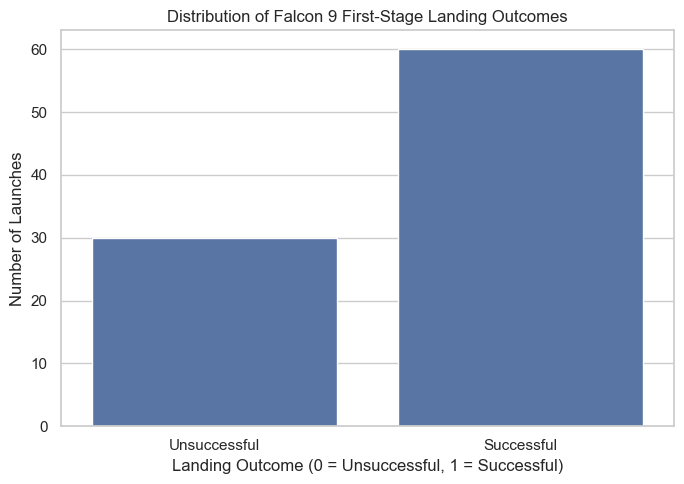

Class
1    60
0    30
Name: count, dtype: int64

Percentage distribution:
Class
1    66.67
0    33.33
Name: proportion, dtype: float64


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(7, 5))
sns.countplot(data=df2, x="Class")
plt.title("Distribution of Falcon 9 First-Stage Landing Outcomes")
plt.xlabel("Landing Outcome (0 = Unsuccessful, 1 = Successful)")
plt.ylabel("Number of Launches")
plt.xticks([0, 1], ["Unsuccessful", "Successful"])
plt.tight_layout()
plt.show()

print(df2["Class"].value_counts())
print("\nPercentage distribution:")
print((df2["Class"].value_counts(normalize=True) * 100).round(2))

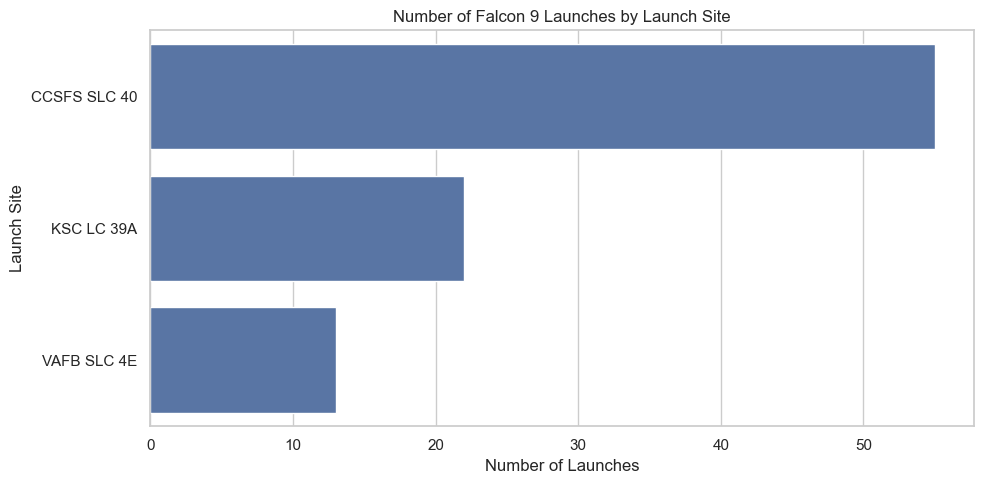

In [17]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df1,
    y="LaunchSite",
    order=df1["LaunchSite"].value_counts().index
)

plt.title("Number of Falcon 9 Launches by Launch Site")
plt.xlabel("Number of Launches")
plt.ylabel("Launch Site")
plt.tight_layout()
plt.show()

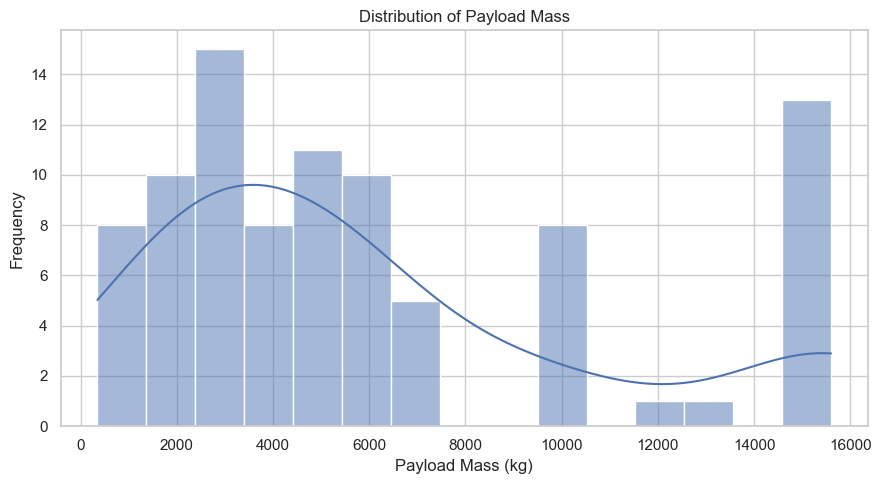

count       90.000000
mean      6123.547647
std       4732.115291
min        350.000000
25%       2510.750000
50%       4701.500000
75%       8912.750000
max      15600.000000
Name: PayloadMass, dtype: float64


In [18]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df1,
    x="PayloadMass",
    bins=15,
    kde=True
)

plt.title("Distribution of Payload Mass")
plt.xlabel("Payload Mass (kg)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print(df1["PayloadMass"].describe())

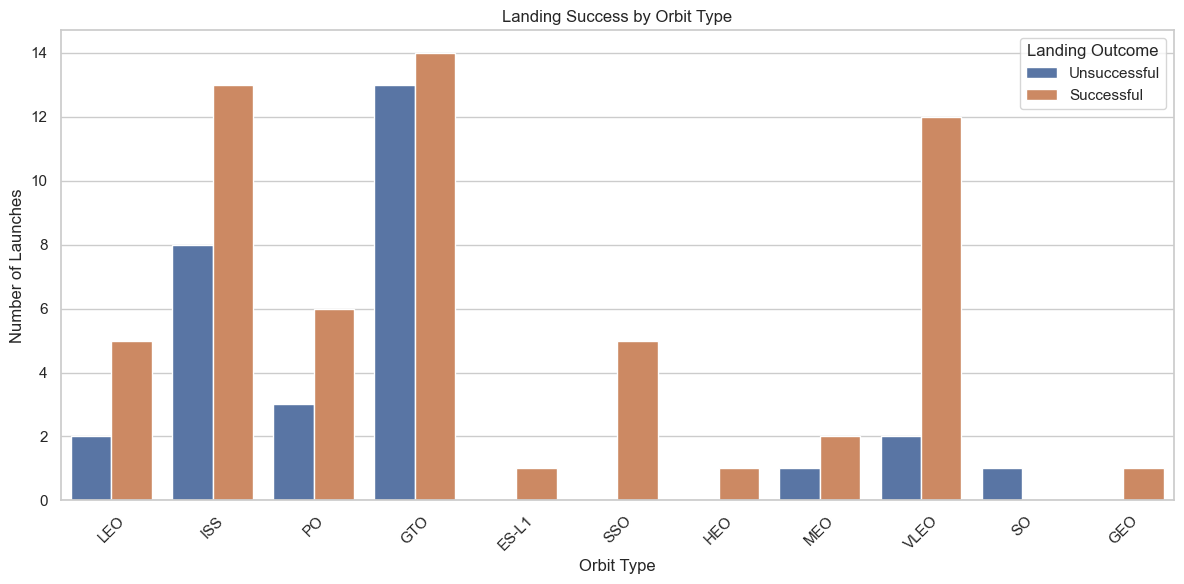

In [19]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df2,
    x="Orbit",
    hue="Class"
)

plt.title("Landing Success by Orbit Type")
plt.xlabel("Orbit Type")
plt.ylabel("Number of Launches")
plt.legend(
    title="Landing Outcome",
    labels=["Unsuccessful", "Successful"]
)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

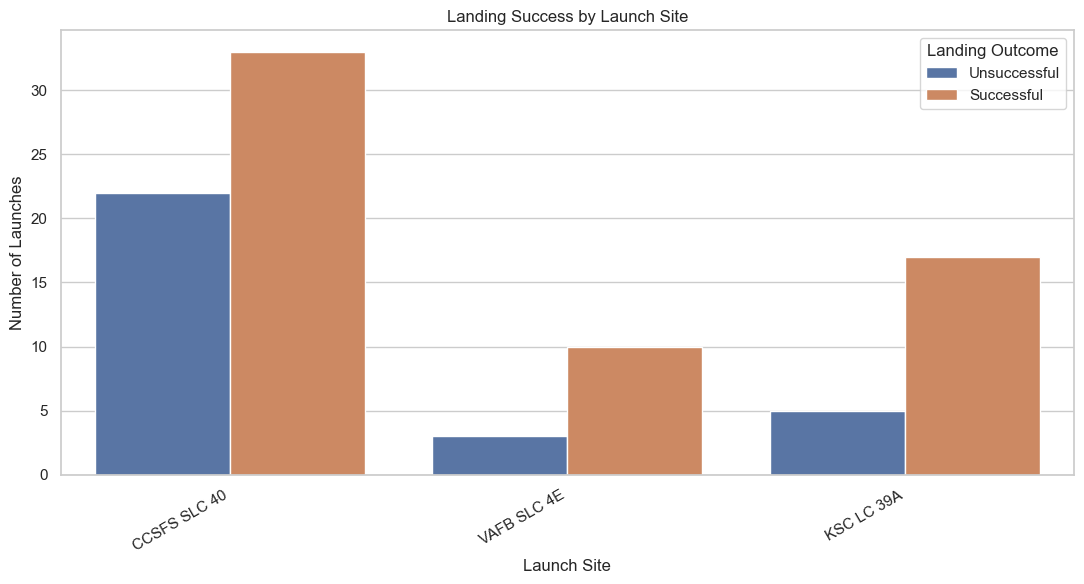

In [20]:
plt.figure(figsize=(11, 6))

sns.countplot(
    data=df2,
    x="LaunchSite",
    hue="Class"
)

plt.title("Landing Success by Launch Site")
plt.xlabel("Launch Site")
plt.ylabel("Number of Launches")
plt.legend(
    title="Landing Outcome",
    labels=["Unsuccessful", "Successful"]
)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

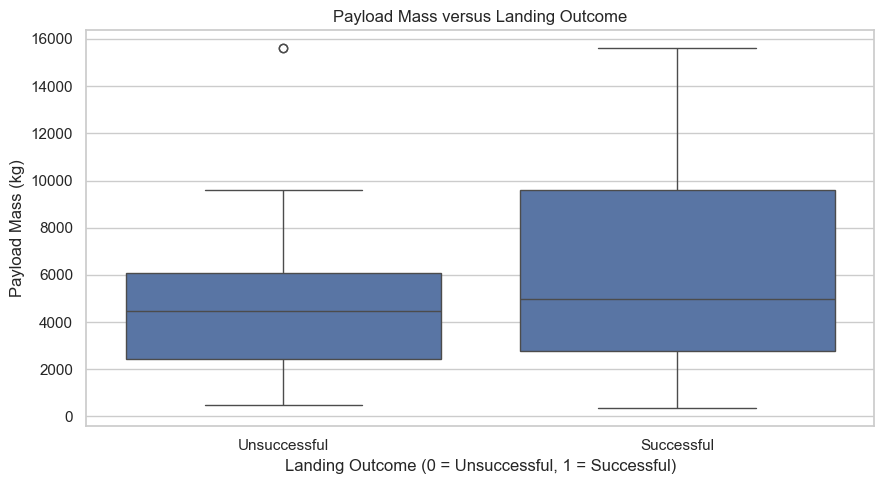

In [21]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df2,
    x="Class",
    y="PayloadMass"
)

plt.title("Payload Mass versus Landing Outcome")
plt.xlabel("Landing Outcome (0 = Unsuccessful, 1 = Successful)")
plt.ylabel("Payload Mass (kg)")
plt.xticks([0, 1], ["Unsuccessful", "Successful"])
plt.tight_layout()
plt.show()

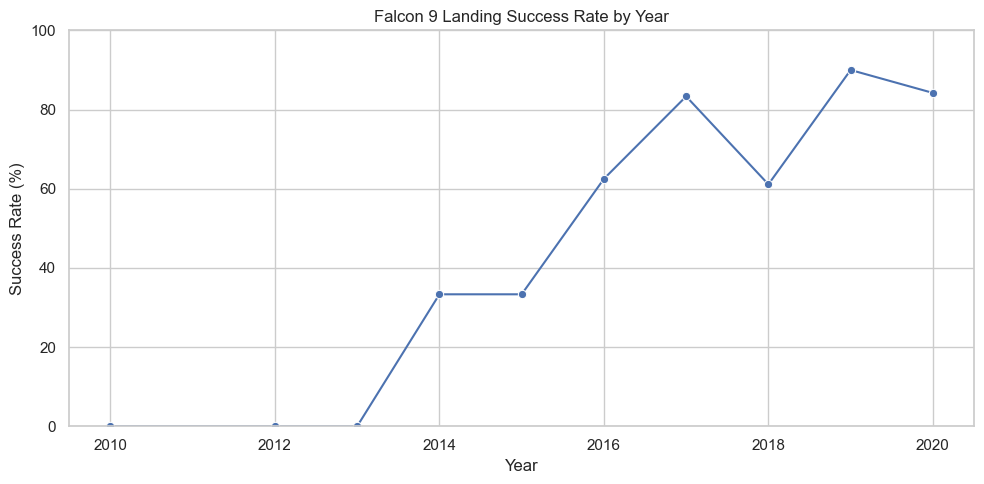

,Year,SuccessRate
0,2010,0.000000
1,2012,0.000000
2,2013,0.000000
3,2014,33.333333
4,2015,33.333333
5,2016,62.500000
6,2017,83.333333
7,2018,61.111111
8,2019,90.000000
9,2020,84.210526


In [22]:
df_eda = df2.copy()

df_eda["Date"] = pd.to_datetime(df_eda["Date"], errors="coerce")
df_eda["Year"] = df_eda["Date"].dt.year

yearly_success = (
    df_eda.groupby("Year")["Class"]
    .mean()
    .mul(100)
    .reset_index(name="SuccessRate")
)

plt.figure(figsize=(10, 5))

sns.lineplot(
    data=yearly_success,
    x="Year",
    y="SuccessRate",
    marker="o"
)

plt.title("Falcon 9 Landing Success Rate by Year")
plt.xlabel("Year")
plt.ylabel("Success Rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

display(yearly_success)

In [23]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

# Prepare features and target
X = df3.copy()
y = df2["Class"].copy()

# Verify the datasets are aligned
assert len(X) == len(y), "Feature and target row counts do not match"

# Remove columns that are constant, if any
X = X.loc[:, X.nunique() > 1]

# Check the prepared data
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("\nTarget distribution:")
print(y.value_counts())
print("\nMissing values in features:", X.isnull().sum().sum())

Feature matrix shape: (90, 80)
Target shape: (90,)

Target distribution:
Class
1    60
0    30
Name: count, dtype: int64

Missing values in features: 0


In [24]:
# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# Define models
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ]),
    "Support Vector Machine": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(random_state=42))
    ]),
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        max_depth=5
    ),
    "K-Nearest Neighbors": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight="balanced"
    )
}

# Train and evaluate
results = []
trained_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1 Score",
    ascending=False
)

display(results_df.round(3))

Training samples: 72
Testing samples: 18


,Model,Accuracy,Precision,Recall,F1 Score
1,Support Vector Machine,0.833,0.800,1.000,0.889
0,Logistic Regression,0.778,0.786,0.917,0.846
2,Decision Tree,0.778,0.786,0.917,0.846
3,K-Nearest Neighbors,0.667,0.667,1.000,0.800
4,Random Forest,0.722,0.769,0.833,0.800


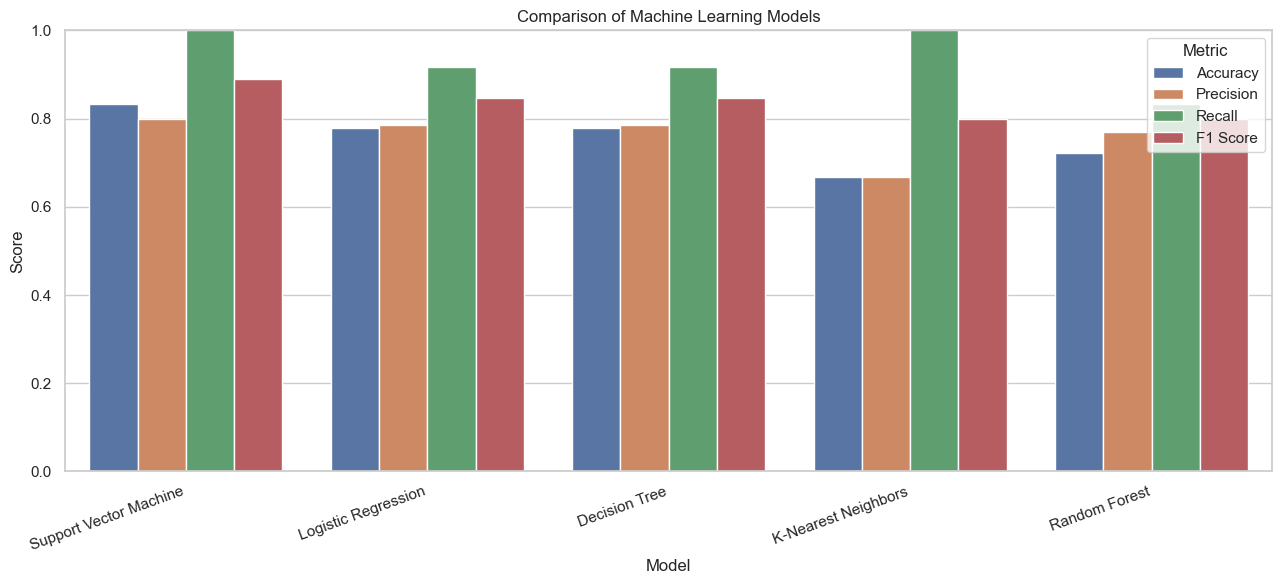

In [25]:
results_long = results_df.melt(
    id_vars="Model",
    value_vars=["Accuracy", "Precision", "Recall", "F1 Score"],
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=results_long,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

Best model by test F1 score: Support Vector Machine

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.50      0.67         6
           1       0.80      1.00      0.89        12

    accuracy                           0.83        18
   macro avg       0.90      0.75      0.78        18
weighted avg       0.87      0.83      0.81        18



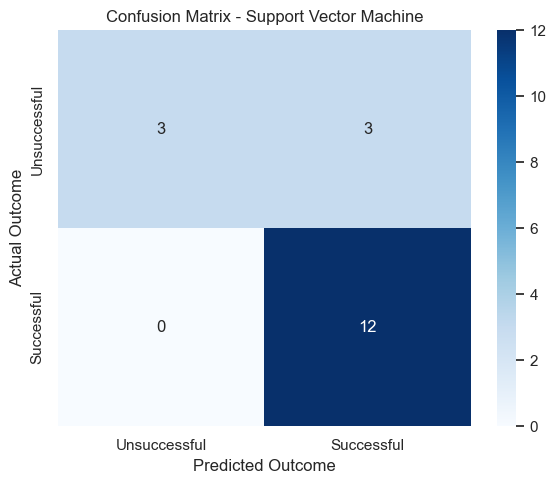

In [26]:
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

y_pred = best_model.predict(X_test)

print("Best model by test F1 score:", best_model_name)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Unsuccessful", "Successful"],
    yticklabels=["Unsuccessful", "Successful"]
)

plt.title(f"Confusion Matrix - {best_model_name}")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")
plt.tight_layout()
plt.show()

In [28]:
print("Dataset shape:", df.shape)
print("\nDataset columns:")
print(df.columns.tolist())

display(df.head())

Dataset shape: (56, 7)

Dataset columns:
['Unnamed: 0', 'Flight Number', 'Launch Site', 'class', 'Payload Mass (kg)', 'Booster Version', 'Booster Version Category']


,Unnamed: 0,Flight Number,Launch Site,class,Payload Mass (kg),Booster Version,Booster Version Category
0,0,1,CCAFS LC-40,0,0.0,F9 v1.0 B0003,v1.0
1,1,2,CCAFS LC-40,0,0.0,F9 v1.0 B0004,v1.0
2,2,3,CCAFS LC-40,0,525.0,F9 v1.0 B0005,v1.0
3,3,4,CCAFS LC-40,0,500.0,F9 v1.0 B0006,v1.0
4,4,5,CCAFS LC-40,0,677.0,F9 v1.0 B0007,v1.0


In [29]:
import pandas as pd
import numpy as np

df = df.copy()

df.drop(columns=["Unnamed: 0"], inplace=True, errors="ignore")

df["Payload Mass (kg)"] = pd.to_numeric(
    df["Payload Mass (kg)"], errors="coerce"
)

df["class"] = pd.to_numeric(df["class"], errors="coerce")

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nLaunch outcome distribution:")
print(df["class"].value_counts())

display(df.head())

Dataset shape: (56, 6)

Missing values:
Flight Number               0
Launch Site                 0
class                       0
Payload Mass (kg)           0
Booster Version             0
Booster Version Category    0
dtype: int64

Duplicate rows: 0

Launch outcome distribution:
class
0    32
1    24
Name: count, dtype: int64


,Flight Number,Launch Site,class,Payload Mass (kg),Booster Version,Booster Version Category
0,1,CCAFS LC-40,0,0.0,F9 v1.0 B0003,v1.0
1,2,CCAFS LC-40,0,0.0,F9 v1.0 B0004,v1.0
2,3,CCAFS LC-40,0,525.0,F9 v1.0 B0005,v1.0
3,4,CCAFS LC-40,0,500.0,F9 v1.0 B0006,v1.0
4,5,CCAFS LC-40,0,677.0,F9 v1.0 B0007,v1.0


In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

site_summary = df.groupby("Launch Site").agg(
    Total_Launches=("class", "count"),
    Successful_Landings=("class", "sum"),
    Average_Payload=("Payload Mass (kg)", "mean")
)

site_summary["Success_Rate"] = (
    site_summary["Successful_Landings"]
    / site_summary["Total_Launches"] * 100
)

display(site_summary.round(2))

,Total_Launches,Successful_Landings,Average_Payload,Success_Rate
Launch Site,,,,
CCAFS LC-40,26,7,2590.88,26.92
CCAFS SLC-40,7,3,3516.66,42.86
KSC LC-39A,13,10,4376.51,76.92
VAFB SLC-4E,10,4,5813.80,40.00


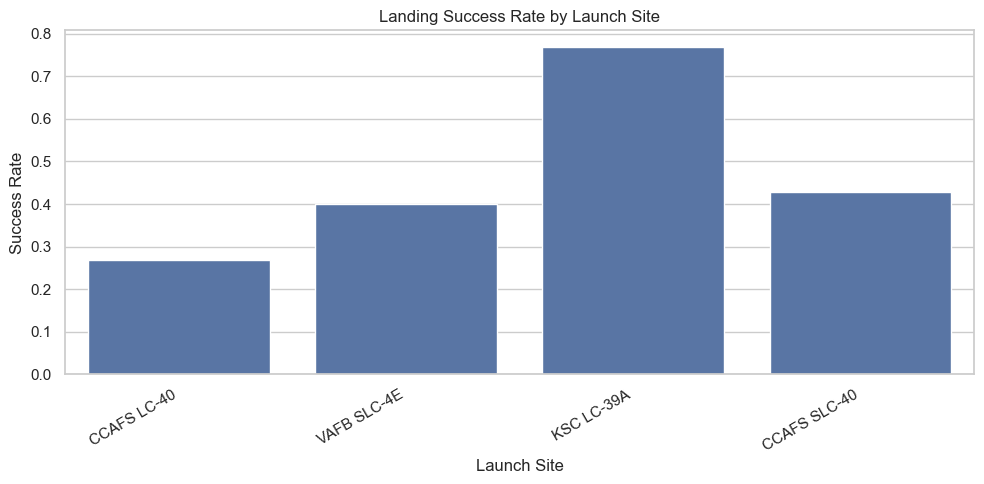

In [31]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="Launch Site",
    y="class",
    errorbar=None
)

plt.title("Landing Success Rate by Launch Site")
plt.xlabel("Launch Site")
plt.ylabel("Success Rate")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

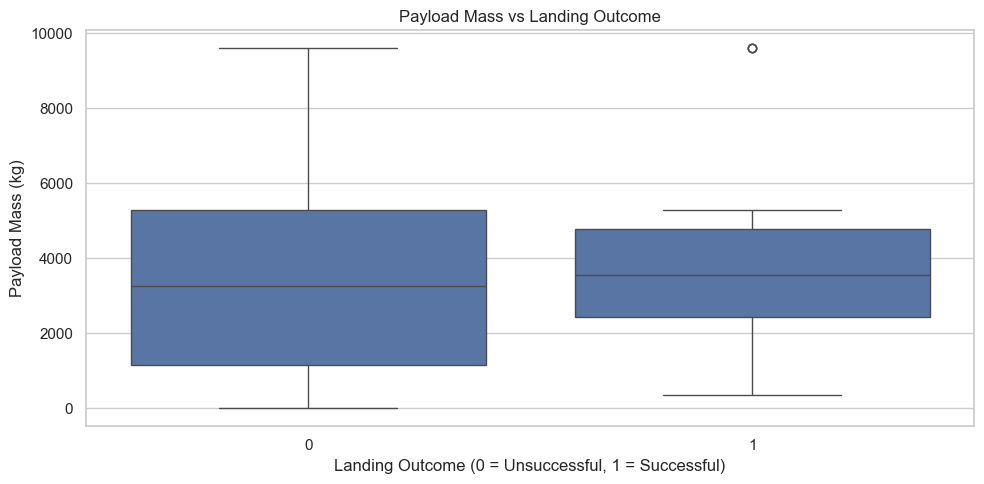

In [32]:
plt.figure(figsize=(10, 5))

sns.boxplot(
    data=df,
    x="class",
    y="Payload Mass (kg)"
)

plt.title("Payload Mass vs Landing Outcome")
plt.xlabel("Landing Outcome (0 = Unsuccessful, 1 = Successful)")
plt.ylabel("Payload Mass (kg)")
plt.tight_layout()
plt.show()

In [33]:
import folium

print("Folium version:", folium.__version__)

Folium version: 0.20.0


In [34]:
import folium

launch_sites = {
    "CCAFS LC-40": {
        "latitude": 28.5619,
        "longitude": -80.5774
    },
    "CCAFS SLC-40": {
        "latitude": 28.5619,
        "longitude": -80.5774
    },
    "KSC LC-39A": {
        "latitude": 28.6082,
        "longitude": -80.6041
    },
    "VAFB SLC-4E": {
        "latitude": 34.632,
        "longitude": -120.611
    }
}

launch_map = folium.Map(
    location=[30, -100],
    zoom_start=4
)

for site, coordinates in launch_sites.items():
    site_data = df[df["Launch Site"] == site]

    if site_data.empty:
        continue

    total_launches = len(site_data)
    successful_landings = int(site_data["class"].sum())
    success_rate = site_data["class"].mean() * 100

    popup_text = f"""
    <b>Launch Site:</b> {site}<br>
    <b>Total Launches:</b> {total_launches}<br>
    <b>Successful Landings:</b> {successful_landings}<br>
    <b>Success Rate:</b> {success_rate:.2f}%
    """

    folium.Marker(
        location=[
            coordinates["latitude"],
            coordinates["longitude"]
        ],
        popup=folium.Popup(popup_text, max_width=300),
        tooltip=site,
        icon=folium.Icon(color="blue", icon="info-sign")
    ).add_to(launch_map)

launch_map

In [35]:

import sqlite3
import pandas as pd

# Create an in-memory SQLite database
conn = sqlite3.connect(":memory:")

# Load the launch dataset into a SQL table
df2.to_sql("SPACEX", conn, if_exists="replace", index=False)

print("SQL database created successfully.")

# Display the table structure
schema = pd.read_sql_query(
    "PRAGMA table_info(SPACEX)",
    conn
)

display(schema)

SQL database created successfully.


,cid,name,type,notnull,dflt_value,pk
0,0,FlightNumber,INTEGER,0,None,0
1,1,Date,TEXT,0,None,0
2,2,BoosterVersion,TEXT,0,None,0
3,3,PayloadMass,REAL,0,None,0
4,4,Orbit,TEXT,0,None,0
5,5,LaunchSite,TEXT,0,None,0
6,6,Outcome,TEXT,0,None,0
7,7,Flights,INTEGER,0,None,0
8,8,GridFins,INTEGER,0,None,0
9,9,Reused,INTEGER,0,None,0


In [36]:
query1 = """
SELECT
    LaunchSite,
    COUNT(*) AS Total_Launches
FROM SPACEX
GROUP BY LaunchSite
ORDER BY Total_Launches DESC;
"""

result1 = pd.read_sql_query(query1, conn)
display(result1)

,LaunchSite,Total_Launches
0,CCSFS SLC 40,55
1,KSC LC 39A,22
2,VAFB SLC 4E,13


In [37]:
query2 = """
SELECT
    LaunchSite,
    COUNT(*) AS Total_Launches,
    SUM(Class) AS Successful_Landings,
    ROUND(100.0 * AVG(Class), 2) AS Success_Rate_Percent
FROM SPACEX
GROUP BY LaunchSite
ORDER BY Success_Rate_Percent DESC;
"""

result2 = pd.read_sql_query(query2, conn)
display(result2)

,LaunchSite,Total_Launches,Successful_Landings,Success_Rate_Percent
0,KSC LC 39A,22,17,77.27
1,VAFB SLC 4E,13,10,76.92
2,CCSFS SLC 40,55,33,60.00


In [38]:
query3 = """
SELECT
    Orbit,
    COUNT(*) AS Total_Launches,
    ROUND(AVG(PayloadMass), 2) AS Average_Payload_Mass,
    SUM(Class) AS Successful_Landings
FROM SPACEX
GROUP BY Orbit
ORDER BY Average_Payload_Mass DESC;
"""

result3 = pd.read_sql_query(query3, conn)
display(result3)

,Orbit,Total_Launches,Average_Payload_Mass,Successful_Landings
0,VLEO,14,15428.57,12
1,PO,9,7583.67,6
2,SO,1,6123.55,0
3,GEO,1,6123.55,1
4,GTO,27,5011.99,14
5,MEO,3,3987.00,2
6,LEO,7,3890.81,5
7,ISS,21,3279.94,13
8,SSO,5,2060.00,5
9,ES-L1,1,570.00,1


In [39]:
query4 = """
SELECT
    Reused,
    COUNT(*) AS Total_Launches,
    SUM(Class) AS Successful_Landings,
    ROUND(100.0 * AVG(Class), 2) AS Success_Rate_Percent
FROM SPACEX
GROUP BY Reused
ORDER BY Reused;
"""

result4 = pd.read_sql_query(query4, conn)
display(result4)

,Reused,Total_Launches,Successful_Landings,Success_Rate_Percent
0,0,53,31,58.49
1,1,37,29,78.38


In [40]:
with pd.ExcelWriter("spacex_sql_analysis.xlsx") as writer:
    result1.to_excel(writer, sheet_name="Launches by Site", index=False)
    result2.to_excel(writer, sheet_name="Success by Site", index=False)
    result3.to_excel(writer, sheet_name="Payload by Orbit", index=False)
    result4.to_excel(writer, sheet_name="Booster Reuse", index=False)

print("SQL analysis results saved to spacex_sql_analysis.xlsx")

SQL analysis results saved to spacex_sql_analysis.xlsx


In [41]:
print("MODEL COMPARISON")
display(results_df.round(3))

print("\nBEST MODEL")
print(results_df.iloc[0]["Model"])

print("\nBEST MODEL METRICS")
print(results_df.iloc[0])

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score
1,Support Vector Machine,0.833,0.800,1.000,0.889
0,Logistic Regression,0.778,0.786,0.917,0.846
2,Decision Tree,0.778,0.786,0.917,0.846
3,K-Nearest Neighbors,0.667,0.667,1.000,0.800
4,Random Forest,0.722,0.769,0.833,0.800



BEST MODEL
Support Vector Machine

BEST MODEL METRICS
Model        Support Vector Machine
Accuracy                   0.833333
Precision                       0.8
Recall                          1.0
F1 Score                   0.888889
Name: 1, dtype: object
